# Dataset Visualization
This notebook visualizes the LLM-generated memory graph dataset for detecting persistent memory poisoning attacks.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path
from matplotlib.patches import Patch

DATA_DIR = Path("../data/raw/llm_generated")

## 1. Dataset Overview

In [2]:
with open(DATA_DIR / "metadata.json") as f:
    metadata = json.load(f)

clean = [m for m in metadata if m["label"] == "clean"]
poisoned = [m for m in metadata if m["label"] == "poisoned"]

print(f"Total sequences: {len(metadata)}")
print(f"  Clean: {len(clean)}")
print(f"  Poisoned: {len(poisoned)}")

# Attack type breakdown
attack_types = {}
for m in poisoned:
    at = m.get("attack_type", "unknown")
    attack_types[at] = attack_types.get(at, 0) + 1
print(f"\nAttack types: {attack_types}")

Total sequences: 300
  Clean: 180
  Poisoned: 120

Attack types: {'minja_query_only': 40, 'direct_write': 40, 'incremental_slow': 40}


## 2. Helper Functions

In [3]:
def load_snapshot(path):
    data = np.load(path)
    return {k: data[k] for k in data.files}

def snapshot_to_networkx(snap):
    G = nx.Graph()
    n = snap["node_features"].shape[0]
    for i in range(n):
        G.add_node(i, poisoned=int(snap["node_labels"][i]))
    edge_index = snap["edge_index"]
    edge_weights = snap["edge_weights"]
    if edge_index.shape[1] > 0:
        for idx in range(0, edge_index.shape[1], 2):
            src, dst = edge_index[0, idx], edge_index[1, idx]
            w = edge_weights[idx] if idx < len(edge_weights) else 0.5
            G.add_edge(int(src), int(dst), weight=float(w))
    return G

def plot_graph(ax, G, title):
    if len(G.nodes) == 0:
        ax.set_title(title)
        ax.text(0.5, 0.5, "Empty", ha="center", va="center", transform=ax.transAxes)
        return
    colors = ["#e74c3c" if G.nodes[n].get("poisoned", 0) == 1 else "#3498db" for n in G.nodes]
    pos = nx.spring_layout(G, seed=42, k=2.0/np.sqrt(len(G.nodes)) if len(G.nodes) < 100 else 0.5)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.2, width=0.5, edge_color="#bdc3c7")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=50, alpha=0.8)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

## 3. Clean vs Poisoned Comparison

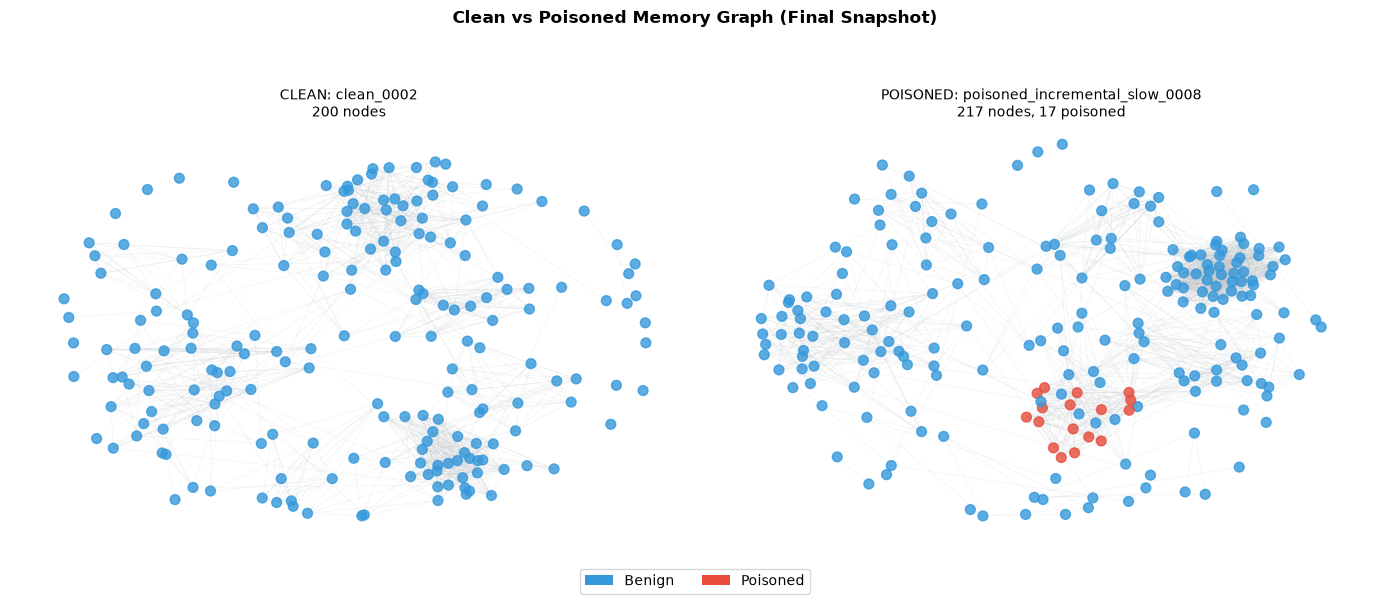

In [7]:
clean_id = clean[0]["sequence_id"]
poisoned_id = poisoned[8]["sequence_id"]

clean_snaps = sorted((DATA_DIR / clean_id).glob("snapshot_*.npz"))
poisoned_snaps = sorted((DATA_DIR / poisoned_id).glob("snapshot_*.npz"))

clean_snap = load_snapshot(clean_snaps[-1])
poisoned_snap = load_snapshot(poisoned_snaps[-1])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

G_clean = snapshot_to_networkx(clean_snap)
G_poisoned = snapshot_to_networkx(poisoned_snap)

n_poisoned_nodes = int(poisoned_snap["node_labels"].sum())
plot_graph(ax1, G_clean, f"CLEAN: {clean_id}\n{len(clean_snap['node_labels'])} nodes")
plot_graph(ax2, G_poisoned, f"POISONED: {poisoned_id}\n{len(poisoned_snap['node_labels'])} nodes, {n_poisoned_nodes} poisoned")

legend = [Patch(facecolor="#3498db", label="Benign"), Patch(facecolor="#e74c3c", label="Poisoned")]
fig.legend(handles=legend, loc="lower center", ncol=2)
fig.suptitle("Clean vs Poisoned Memory Graph (Final Snapshot)", fontweight="bold")
plt.tight_layout(rect=[0, 0.05, 1, 0.93])
plt.show()

## 4. Graph Evolution Over Time (Poisoned Sequence)

In [ ]:
seq_id = poisoned[0]["sequence_id"]
snapshots = sorted((DATA_DIR / seq_id).glob("snapshot_*.npz"))

indices = np.linspace(0, len(snapshots)-1, min(8, len(snapshots)), dtype=int)
selected = [snapshots[i] for i in indices]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, (snap_path, ax) in enumerate(zip(selected, axes)):
    snap = load_snapshot(snap_path)
    G = snapshot_to_networkx(snap)
    n_poisoned = int(snap["node_labels"].sum())
    label = "POISONED" if snap["graph_label"][0] == 1 else "CLEAN"
    plot_graph(ax, G, f"t={indices[i]} | {label}\n{len(snap['node_labels'])} nodes, {n_poisoned} poisoned")

for i in range(len(selected), len(axes)):
    axes[i].axis("off")

legend = [Patch(facecolor="#3498db", label="Benign"), Patch(facecolor="#e74c3c", label="Poisoned")]
fig.legend(handles=legend, loc="lower center", ncol=2)
fig.suptitle(f"Memory Graph Evolution: {seq_id}", fontweight="bold")
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

## 5. Dataset Statistics

In [ ]:
clean_nodes, poisoned_nodes = [], []
clean_edges, poisoned_edges = [], []

for m in metadata:
    seq_dir = DATA_DIR / m["sequence_id"]
    snaps = sorted(seq_dir.glob("snapshot_*.npz"))
    if not snaps:
        continue
    last = load_snapshot(snaps[-1])
    n_nodes = last["node_features"].shape[0]
    n_edges = last["edge_index"].shape[1] // 2 if last["edge_index"].shape[1] > 0 else 0
    if m["label"] == "clean":
        clean_nodes.append(n_nodes)
        clean_edges.append(n_edges)
    else:
        poisoned_nodes.append(n_nodes)
        poisoned_edges.append(n_edges)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Node distribution
axes[0,0].hist(clean_nodes, bins=20, alpha=0.7, label="Clean", color="#3498db")
axes[0,0].hist(poisoned_nodes, bins=20, alpha=0.7, label="Poisoned", color="#e74c3c")
axes[0,0].set_xlabel("Number of nodes")
axes[0,0].set_ylabel("Count")
axes[0,0].set_title("Node Count Distribution")
axes[0,0].legend()

# Edge distribution
axes[0,1].hist(clean_edges, bins=20, alpha=0.7, label="Clean", color="#3498db")
axes[0,1].hist(poisoned_edges, bins=20, alpha=0.7, label="Poisoned", color="#e74c3c")
axes[0,1].set_xlabel("Number of edges")
axes[0,1].set_ylabel("Count")
axes[0,1].set_title("Edge Count Distribution")
axes[0,1].legend()

# Evolution over time
seq_dir = DATA_DIR / poisoned[0]["sequence_id"]
snaps = sorted(seq_dir.glob("snapshot_*.npz"))
timestamps, node_counts, poisoned_counts = [], [], []
for snap_path in snaps:
    snap = load_snapshot(snap_path)
    timestamps.append(snap["timestamp"][0])
    node_counts.append(snap["node_features"].shape[0])
    poisoned_counts.append(int(snap["node_labels"].sum()))

axes[1,0].plot(timestamps, node_counts, "b-", label="Total nodes")
axes[1,0].plot(timestamps, poisoned_counts, "r-", label="Poisoned nodes")
axes[1,0].set_xlabel("Timestamp")
axes[1,0].set_ylabel("Count")
axes[1,0].set_title(f"Evolution: {poisoned[0]['sequence_id']}")
axes[1,0].legend()

# Attack type breakdown
axes[1,1].bar(attack_types.keys(), attack_types.values(), color=["#e74c3c", "#f39c12", "#9b59b6"])
axes[1,1].set_xlabel("Attack Type")
axes[1,1].set_ylabel("Count")
axes[1,1].set_title("Attack Type Distribution")
axes[1,1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

## 6. Sample Snapshot Structure

In [ ]:
sample = load_snapshot(poisoned_snaps[-1])
print("Snapshot contents:")
for k, v in sample.items():
    print(f"  {k}: shape={v.shape}, dtype={v.dtype}")

print(f"\nNode features: 384-dim embedding + 4 meta features = {sample['node_features'].shape[1]} dims")
print(f"Graph label: {sample['graph_label'][0]} (0=clean, 1=poisoned)")
print(f"Poisoned nodes: {int(sample['node_labels'].sum())} / {len(sample['node_labels'])}")